In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("MUC02_Credit_PreScreening_Dataset.csv")

# Display the first five records
df.head()

,application_id,application_date,age,gender,city,city_tier,employment_type,years_in_current_job,monthly_income,existing_emi,credit_score,credit_history_months,num_active_loans,delinquencies_24m,loan_purpose,loan_amount,tenure_months,proposed_emi,decision
0,APP100001,2026-04-01,28,Male,Hyderabad,1,Salaried,4.1,95000.0,23500.0,784.0,109,2,0,Home Renovation,240000.0,48,6600.0,Approved
1,APP100002,2026-04-01,36,Female,Raipur,3,Business Owner,0.6,43000.0,8500.0,790.0,162,2,0,Wedding,145000.0,36,5000.0,Approved
2,APP100003,2026-04-01,35,Male,Nagpur,2,Salaried,4.4,35000.0,3500.0,718.0,151,1,1,Medical,345000.0,36,11800.0,Approved
3,APP100004,2026-04-01,42,Male,Jaipur,2,Salaried,5.8,44500.0,0.0,NaN,0,0,0,Travel,135000.0,36,4600.0,Approved
4,APP100005,2026-04-01,34,Male,Kochi,2,Self-Employed Professional,2.1,83500.0,6000.0,700.0,127,1,3,Medical,700000.0,24,33600.0,Declined


In [2]:
# Create a working copy
df_clean = df.copy()

In [3]:
# Dataset dimensions
print("Dataset shape:", df_clean.shape)

# Column names
print("\nColumn names:")
print(df_clean.columns.tolist())

# Data types and non-null counts
print("\nDataset information:")
df_clean.info()

# Summary statistics for numerical columns
print("\nNumerical summary:")
display(df_clean.describe().T)

# Summary of categorical columns
print("\nCategorical summary:")
display(df_clean.describe(include="object").T)

Dataset shape: (12000, 19)

Column names:
['application_id', 'application_date', 'age', 'gender', 'city', 'city_tier', 'employment_type', 'years_in_current_job', 'monthly_income', 'existing_emi', 'credit_score', 'credit_history_months', 'num_active_loans', 'delinquencies_24m', 'loan_purpose', 'loan_amount', 'tenure_months', 'proposed_emi', 'decision']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   application_id         12000 non-null  str    
 1   application_date       12000 non-null  str    
 2   age                    12000 non-null  int64  
 3   gender                 12000 non-null  str    
 4   city                   12000 non-null  str    
 5   city_tier              12000 non-null  int64  
 6   employment_type        12000 non-null  str    
 7   years_in_current_job   12000 non-null  float64
 8   m

,count,mean,std,min,25%,50%,75%,max
age,12000.0,33.153750,7.058878,21.0,28.0,33.0,38.0,60.0
city_tier,12000.0,1.707917,0.757728,1.0,1.0,2.0,2.0,3.0
years_in_current_job,12000.0,3.774850,3.149578,0.0,1.5,3.0,5.1,30.0
monthly_income,11559.0,60314.862877,48890.827938,12000.0,33500.0,50500.0,74750.0,1656000.0
existing_emi,12000.0,6273.166667,8526.169300,0.0,0.0,4000.0,8500.0,96500.0
credit_score,10961.0,725.920080,62.559023,479.0,684.0,726.0,769.0,890.0
credit_history_months,12000.0,114.880167,77.329483,0.0,54.0,114.0,169.0,395.0
num_active_loans,12000.0,1.166000,1.148356,0.0,0.0,1.0,2.0,8.0
delinquencies_24m,12000.0,0.775750,1.227024,0.0,0.0,0.0,1.0,11.0
loan_amount,12000.0,379592.500000,295073.073639,50000.0,175000.0,300000.0,490000.0,2500000.0



Categorical summary:


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_10688\2522243736.py:18: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df_clean.describe(include="object").T)


,count,unique,top,freq
application_id,12000,12000,APP100001,1
application_date,12000,183,2026-06-28,98
gender,12000,2,Male,8205
city,12000,26,Bengaluru,746
employment_type,12000,4,Salaried,7057
loan_purpose,12000,7,Debt Consolidation,2370
decision,12000,2,Approved,6353


In [4]:
# Count missing values in each column
missing_count = df_clean.isnull().sum()

# Calculate missing-value percentage
missing_percentage = (
    df_clean.isnull().mean() * 100
).round(2)

missing_summary = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percentage": missing_percentage
})

# Display columns with missing values
display(
    missing_summary[missing_summary["Missing_Count"] > 0]
    .sort_values("Missing_Count", ascending=False)
)

,Missing_Count,Missing_Percentage
credit_score,1039,8.66
monthly_income,441,3.68


In [5]:
# Check credit history for applicants with missing credit scores
missing_score = df_clean["credit_score"].isna()

display(
    df_clean.loc[
        missing_score,
        ["credit_score", "credit_history_months"]
    ]["credit_history_months"]
    .value_counts()
    .rename_axis("credit_history_months")
    .reset_index(name="applicant_count")
)

,credit_history_months,applicant_count
0,0,1039


In [6]:
# Count missing monthly income by employment type
income_missing = (
    df_clean[df_clean["monthly_income"].isna()]
    .groupby("employment_type")
    .size()
    .sort_values(ascending=False)
)

print(income_missing)

employment_type
Business Owner                227
Self-Employed Professional    154
Salaried                       49
Gig / Contract                 11
dtype: int64


In [7]:
# Compare income statistics across employment types
display(
    df_clean.groupby("employment_type")["monthly_income"]
    .agg(["count", "median", "mean", "min", "max"])
    .round(2)
)

,count,median,mean,min,max
employment_type,,,,,
Business Owner,1522,69500.0,79441.52,12000.0,330000.0
Gig / Contract,1755,28000.0,32152.14,12000.0,170000.0
Salaried,7008,50000.0,58827.34,12000.0,1656000.0
Self-Employed Professional,1274,75000.0,84443.09,12000.0,349000.0


In [8]:
# Inspect income distribution
display(
    df_clean["monthly_income"]
    .describe(percentiles=[0.90, 0.95, 0.99, 0.995])
    .to_frame()
)

# Inspect the 15 highest income records
display(
    df_clean.nlargest(15, "monthly_income")[
        [
            "application_id",
            "employment_type",
            "monthly_income",
            "existing_emi",
            "credit_score",
            "loan_amount",
            "decision"
        ]
    ]
)

,monthly_income
count,1.155900e+04
mean,6.031486e+04
std,4.889083e+04
min,1.200000e+04
90%,1.060000e+05
95%,1.300000e+05
99%,1.910000e+05
99.5%,2.342100e+05
max,1.656000e+06


,application_id,employment_type,monthly_income,existing_emi,credit_score,loan_amount,decision
1467,APP101468,Salaried,1656000.0,16500.0,718.0,925000.0,Declined
300,APP100301,Salaried,1254000.0,0.0,NaN,240000.0,Approved
2493,APP102494,Salaried,1212000.0,23500.0,718.0,600000.0,Approved
589,APP100590,Salaried,1068000.0,13500.0,700.0,600000.0,Declined
9849,APP109850,Salaried,990000.0,21000.0,633.0,260000.0,Declined
1848,APP101849,Salaried,984000.0,0.0,NaN,500000.0,Approved
2488,APP102489,Salaried,972000.0,0.0,695.0,310000.0,Approved
4010,APP104011,Salaried,900000.0,4000.0,789.0,580000.0,Approved
4898,APP104899,Salaried,870000.0,4500.0,682.0,645000.0,Declined
9261,APP109262,Salaried,702000.0,0.0,740.0,495000.0,Approved


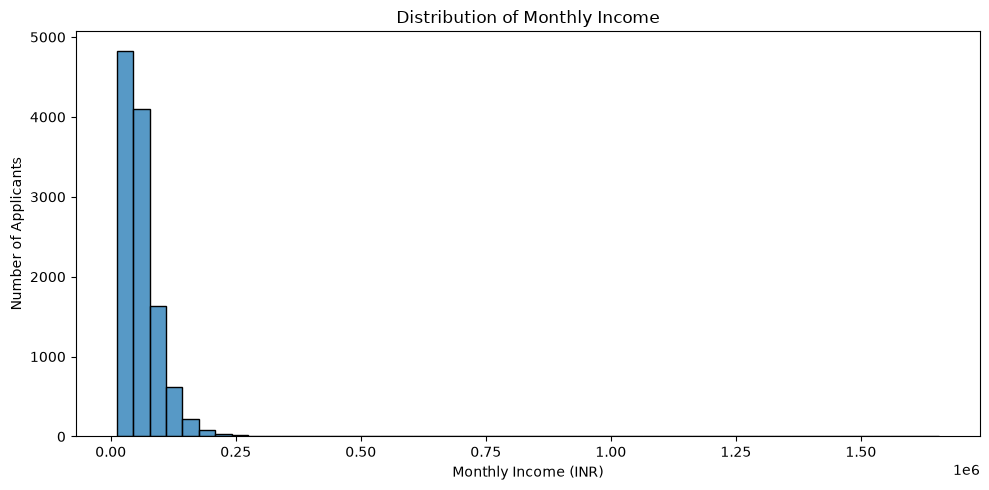

In [9]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x="monthly_income",
    bins=50
)

plt.title("Distribution of Monthly Income")
plt.xlabel("Monthly Income (INR)")
plt.ylabel("Number of Applicants")
plt.tight_layout()
plt.show()

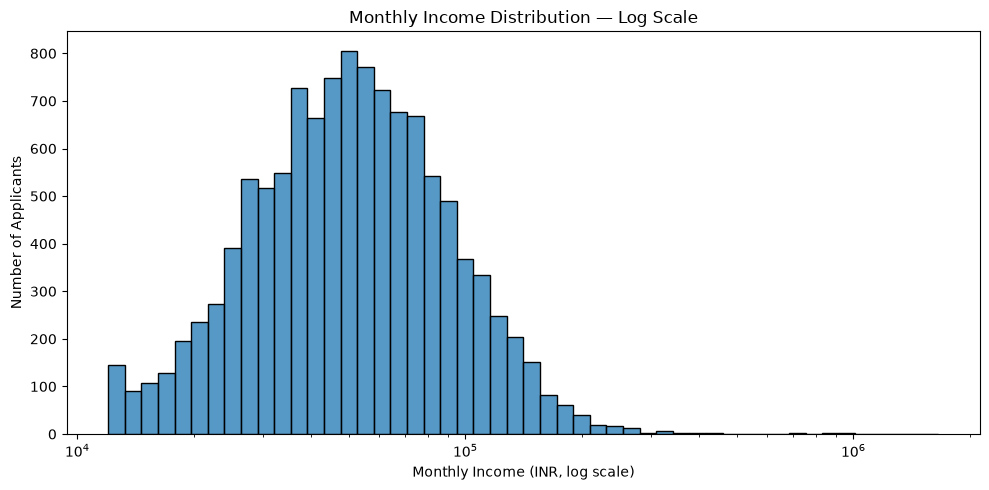

In [10]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x="monthly_income",
    bins=50,
    log_scale=True
)

plt.title("Monthly Income Distribution — Log Scale")
plt.xlabel("Monthly Income (INR, log scale)")
plt.ylabel("Number of Applicants")
plt.tight_layout()
plt.show()

In [11]:
# Convert application_date to datetime
df_clean["application_date"] = pd.to_datetime(
    df_clean["application_date"],
    errors="coerce"
)

# Verify conversion and date range
print("Date dtype:", df_clean["application_date"].dtype)
print("Invalid dates:", df_clean["application_date"].isna().sum())
print("Earliest date:", df_clean["application_date"].min())
print("Latest date:", df_clean["application_date"].max())

Date dtype: datetime64[us]
Invalid dates: 0
Earliest date: 2026-04-01 00:00:00
Latest date: 2026-09-30 00:00:00


In [12]:
# Count historical decisions
decision_counts = df_clean["decision"].value_counts()

# Calculate percentages
decision_percentages = (
    df_clean["decision"].value_counts(normalize=True) * 100
).round(2)

decision_summary = pd.DataFrame({
    "Count": decision_counts,
    "Percentage": decision_percentages
})

display(decision_summary)

,Count,Percentage
decision,,
Approved,6353,52.94
Declined,5647,47.06


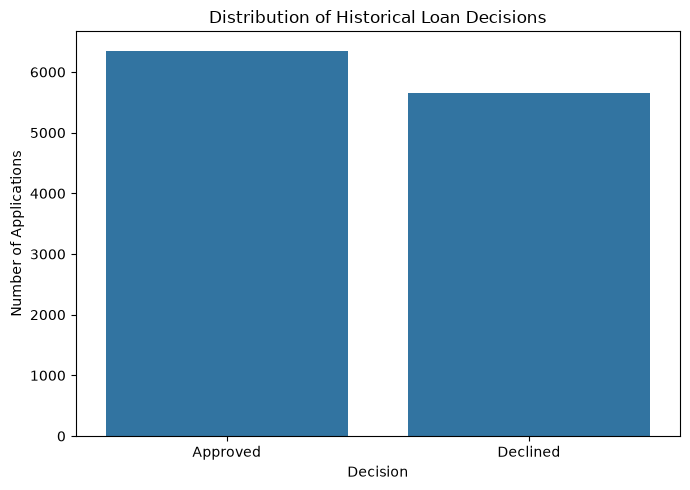

In [13]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x="decision"
)

plt.title("Distribution of Historical Loan Decisions")
plt.xlabel("Decision")
plt.ylabel("Number of Applications")
plt.tight_layout()
plt.show()